# ML pipeline

Checklist **V6.6**: step 14 (the split) freezes the holdout right after Gold acceptance, before the target-guided Gold EDA (steps 15–17), then section 03 (steps 18–23).

| Step | Section | Output |
|---|---|---|
| 14 | Train / validation / test + out-of-time split (`util/ml_split.py`) | `datamart/gold/split/v1/`: `split_manifest.csv`, `split_summary.csv`, `split_config.yaml` |
| 15–17 | Gold EDA (feature/target on train, findings → actions, temporal quality) | `datamart/gold/_eda/` |
| 18–23 | Feature engineering, filtering, preprocessing | `datamart/ml/` |
| 24–32 | Model development, final evaluation, error/robustness analysis | `datamart/ml/model_development/v1/` |
| 33–36 | Model registry (MLflow), monthly batch inference from `@champion`, monitoring, governance / refresh SOP / rollback | `datamart/ml/mlflow/`, `datamart/gold/model_predictions/`, `datamart/ml/deployment/v1/` |

In [1]:
import os, sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import yaml
from pyspark.sql import functions as F
from sklearn.model_selection import train_test_split

# Project folder: /app inside the Docker container, otherwise the parent of this notebook's folder (script/)
PROJECT_DIR = os.environ.get("PROJECT_DIR") or ("/app" if os.path.isdir("/app/data") else os.path.abspath(".."))
sys.path.insert(0, PROJECT_DIR)
from util import dataprocessing_bronze as bronze      # Spark session

GOLD_DIR = os.path.join(PROJECT_DIR, "datamart", "gold")
with open(os.path.join(PROJECT_DIR, "config", "data_contract.yaml"), encoding="utf-8") as f:
    CONTRACT = yaml.safe_load(f)
LABEL_DEF = CONTRACT["target"]["label_def"]
SCORING_COL = CONTRACT["scoring_timestamp"]["column"]

spark = bronze.get_spark("mlpipeline")

---

## Step 14 — Train / validation / test + out-of-time split

**Design** (agreed):

1. **Out-of-time (OOT) holdout, by time:** loans starting **2024-07 → 2025-01**. Used **once**, in step 31.
2. **Development period 2023-01 → 2024-06:** random split **stratified by label** into
   - **train 70%** — fitting, cross-validation, feature/target EDA (step 15),
   - **validation 15%** — early stopping, threshold choice, model comparison,
   - **test 15%** — in-time check of the frozen model (step 30/31).

**Why this design:** the model scores *future* applications, so the final estimate must come from later loans the model never saw (OOT); inside the development period a stratified random split gives balanced, stable train/validation/test sets. Comparing in-time test vs OOT shows how much performance drifts.

**Eligibility:** only loans with a **mature** label (contract). **Group rule:** a customer may appear in one partition only (here one loan per customer, so this holds by construction — asserted so a future repeat customer cannot slip through).

--- step14 ---


Eligible loans (mature labels): 12,500
Development-period label rate: 28.87%


Saved: ['split_checks.csv', 'split_config.yaml', 'split_manifest.csv', 'split_summary.csv']
--- step14 done in 3s


,loans
partition,
train,6281
validation,1346
test,1347
oot,3526


partition,loans,positives,first_loan_start,last_loan_start,cohorts,share_of_all_pct,share_of_dev_pct,label_rate_pct,with_clickstream_pct
train,"6,281","1,813",2023-01,2024-06,18,50.2%,70.0%,28.86%,100%
validation,"1,346",389,2023-01,2024-06,18,10.8%,15.0%,28.90%,100%
test,"1,347",389,2023-01,2024-06,18,10.8%,15.0%,28.88%,100%
oot,"3,526","1,011",2024-07,2025-01,7,28.2%,—,28.67%,0%


check,status,observed,rule
each eligible loan in exactly one partition,PASS,"12,500 assigned, 0 duplicates","all eligible, no duplicates"
zero customer overlap between partitions,PASS,0 customers in more than one partition,0
no temporal overlap: development before OOT,PASS,"last development loan 2024-06, first OOT loan 2024-07",dev < 2024-07 <= OOT
stratification: train label rate,PASS,28.86% vs development 28.87% (gap 0.01 pp),<= 1.0 pp
stratification: validation label rate,PASS,28.90% vs development 28.87% (gap 0.03 pp),<= 1.0 pp
stratification: test label rate,PASS,28.88% vs development 28.87% (gap 0.01 pp),<= 1.0 pp
size: train,PASS,70.0% of development,70% ± 1.0 pp
size: validation,PASS,15.0% of development,15% ± 1.0 pp
size: test,PASS,15.0% of development,15% ± 1.0 pp
reproducible with the same seed,PASS,identical assignment,identical


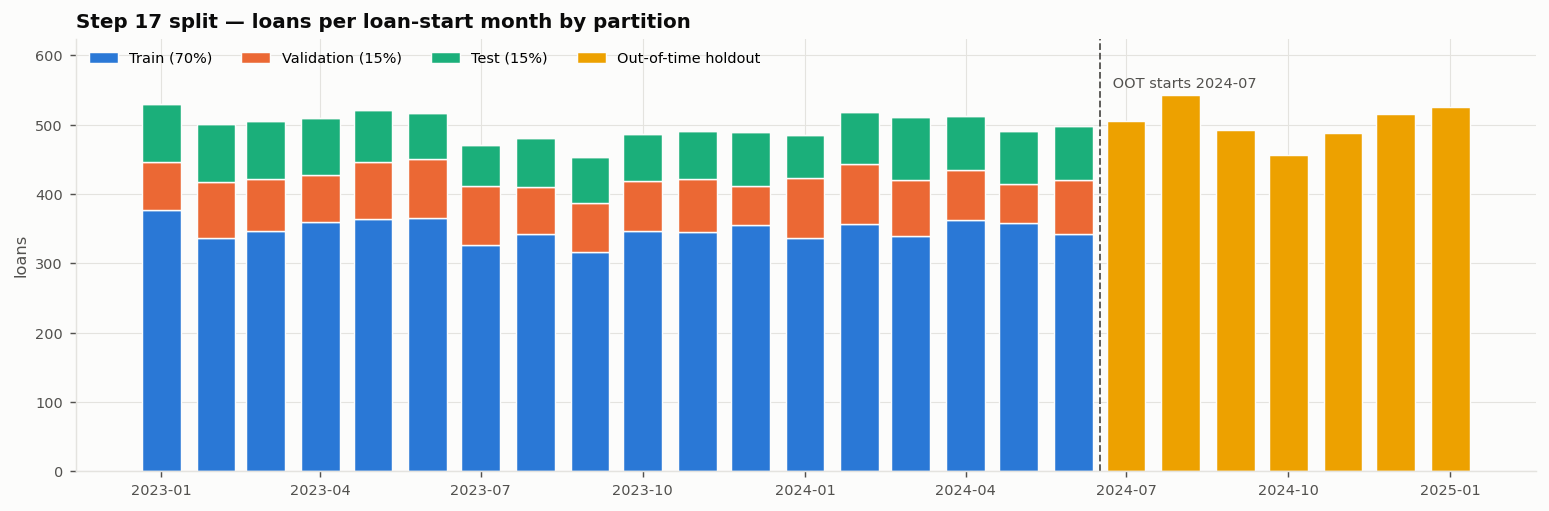

In [2]:
from util import ml_split            # developed in notebooks/ml_split.ipynb (charts and explanations there)
from IPython.display import Image

ml_split.run(spark)
display(ml_split.manifest["partition"].value_counts().reindex(["train", "validation", "test", "oot"]).to_frame("loans"))
display(ml_split.summary.style.hide(axis="index").format(
    {"loans": "{:,}", "positives": "{:,}", "share_of_all_pct": "{:.1f}%", "share_of_dev_pct": "{:.1f}%",
     "label_rate_pct": "{:.2f}%", "with_clickstream_pct": "{:.0f}%"}, na_rep="—"))
display(ml_split.split_checks.style.hide(axis="index"))
Image(filename=os.path.join(ml_split.CHART_DIR, "17_split_by_cohort.png"), width=1000)

### Step 14 summary

- **Frozen holdout:** OOT = loans starting 2024-07 → 2025-01, untouched until step 31. Also note it is the period **without clickstream** — the main model is the one without clickstream; a clickstream challenger needs its own late window inside development.
- **Development:** stratified 70 / 15 / 15 train / validation / test, seed 42, label rates within 1 pp.
- **Manifest** (`datamart/gold/split/v1/split_manifest.csv`): every loan's partition, with dates, label, seed and version — every later step reads its rows from here.
- **Next:** the Gold EDA (steps 15–17) on the frozen split.

---

## Gold EDA — steps 15, 16, 17 (after the split)

Runs `util/dataprocessing_gold.py` (developed in `notebooks/dataprocessing_gold.ipynb`): feature/target EDA on **train only**, temporal quality, and the EDA action register with the Gate 2 check. Charts are written to `datamart/gold/_eda/charts/`; the notebook version shows them with explanations.

In [8]:
from util import dataprocessing_gold as gold

eda = gold.run_eda(spark, charts=True)
rel = eda["step14"]["relationships"]
print("Top 10 features by IV (train):")
display(rel.head(10)[["feature", "group", "iv", "iv_strength", "auc"]].style.hide(axis="index")
        .format({"iv": "{:.3f}", "auc": "{:.3f}"}))
print("Temporal quality:", eda["step16"]["temporal_report"]["status"].value_counts().to_dict())
print("Action register:", eda["step15"]["action_register"]["status"].value_counts().to_dict())
eda["step15"]["gate2"].style.hide(axis="index")

Top 10 features by IV (train):


feature,group,iv,iv_strength,auc
Outstanding_Debt,financials,0.865,suspicious (>0.5),0.725
Interest_Rate,financials,0.698,suspicious (>0.5),0.715
Num_Credit_Inquiries,financials,0.580,suspicious (>0.5),0.709
Delay_from_due_date,financials,0.560,suspicious (>0.5),0.698
credit_history_age_months,financials,0.492,strong,0.690
Num_Credit_Card,financials,0.455,strong,0.678
num_loan_types,financials,0.439,strong,0.671
Num_of_Loan,financials,0.420,strong,0.671
Credit_Mix,financials,0.410,strong,0.680
Num_Bank_Accounts,financials,0.407,strong,0.660


Temporal quality: {'PASS': 14, 'WARN': 5, 'INFO': 1}
Action register: {'closed': 34, 'accepted': 13, 'assigned': 9}


criterion,evidence,status
Gold grain and time rules verified,"step 13: one row per loan, point-in-time 0 violations, outcome = loan start + 6 months, no label in X; step 11 historical replay",PASS
EDA findings resolved or assigned,"56 findings: closed 34, accepted 13, assigned 9; none open",PASS
Leakage risks documented,"leakage watchlist (12 entries) with actions; 4 strong financial features accepted with rationale (AUC < 0.75, known at application)",PASS


---

## Section 03 — feature engineering (steps 21 → 23 → 18)

Runs `util/ml_feature_engineering.py` (developed in `notebooks/ml_feature_engineering.ipynb`). Step 19 skipped (replaced by 21); 20 and 22 not applied.

- **21** OpenFE on model-A features, **train only**, row-wise operators → `autofe_catalog.csv` (20 formulas)
- **23** (V6.6) train-only screens as flags (missing, low variance, duplicates, leakage, correlation, VIF; ACF N/A), model-specific keep/drop (tree / linear) with validation impact → `filtered_features.json` (`A_raw` = raw-only baseline, `A_fe`, `B_raw`, `B_fe`)
- **18** preprocessing fitted on train, one per feature set × model type → `datamart/ml/preprocessing/v1/*.joblib`, with fit/transform tests

In [9]:
from util import ml_feature_engineering as fe

fe_out = fe.run(spark, charts=True, tests=True)
print(f"Generated features kept: {len(fe_out['step21']['catalog'])}")
print("Feature sets:", {k: {m: len(v) for m, v in d.items()} for k, d in fe_out["step23"]["feature_sets"].items()})
display(fe_out["step23"]["impact"].style.hide(axis="index").format({c: "{:.4f}" for c in fe_out["step23"]["impact"].columns if "auc" in c}))
display(fe_out["step18"]["manifest"].style.hide(axis="index"))
fe_out["gate3"].style.hide(axis="index")

  0%|          | 0/16 [00:00<?, ?it/s]

  6%|▋         | 1/16 [00:01<00:22,  1.53s/it]

 31%|███▏      | 5/16 [00:01<00:03,  3.54it/s]

 50%|█████     | 8/16 [00:01<00:01,  5.95it/s]

 62%|██████▎   | 10/16 [00:02<00:00,  7.27it/s]

...

100%|██████████| 16/16 [00:01<00:00, 10.74it/s]

Preprocessing tests passed for all 8 fitted preprocessors
Generated features kept: 20
Feature sets: {'A_raw': {'tree': 46, 'linear': 43}, 'A_fe': {'tree': 66, 'linear': 51}, 'B_raw': {'tree': 66, 'linear': 63}, 'B_fe': {'tree': 86, 'linear': 71}}


feature_set,model_type,features after filtering,features before filtering,val_pr_auc after filtering,val_pr_auc before filtering,val_roc_auc after filtering,val_roc_auc before filtering,delta_roc_auc,delta_pr_auc
A_fe,linear,51.000000,68.000000,0.5844,0.6158,0.7628,0.7745,-0.0116,-0.0314
A_fe,tree,66.000000,68.000000,0.6051,0.6051,0.7894,0.7894,0.0000,0.0000
A_raw,linear,43.000000,48.000000,0.5772,0.5810,0.7603,0.7610,-0.0006,-0.0037
A_raw,tree,46.000000,48.000000,0.6257,0.6257,0.8074,0.8074,0.0000,0.0000
B_fe,linear,71.000000,88.000000,0.6017,0.6250,0.7741,0.7847,-0.0106,-0.0232
B_fe,tree,86.000000,88.000000,0.6404,0.6404,0.8089,0.8089,0.0000,0.0000
B_raw,linear,63.000000,68.000000,0.5962,0.5963,0.7716,0.7726,-0.0010,-0.0001
B_raw,tree,66.000000,68.000000,0.6510,0.6510,0.8189,0.8189,0.0000,0.0000


feature_set,model_type,input_features,output_columns,file
A_raw,tree,46,72,preprocess__A_raw__tree.joblib
A_raw,linear,43,69,preprocess__A_raw__linear.joblib
A_fe,tree,66,110,preprocess__A_fe__tree.joblib
A_fe,linear,51,86,preprocess__A_fe__linear.joblib
B_raw,tree,66,92,preprocess__B_raw__tree.joblib
B_raw,linear,63,89,preprocess__B_raw__linear.joblib
B_fe,tree,86,130,preprocess__B_fe__tree.joblib
B_fe,linear,71,106,preprocess__B_fe__linear.joblib


criterion,status,evidence
Time-safe features,PASS,"all inputs as-of loan_start_date (Gold step 13); generated features are row-wise formulas of those inputs; no temporal / time-series features (steps 20, 22 not applied; ACF N/A)"
Train-only transformations and filtering,PASS,"OpenFE fitted on train; step-23 screens and VIF on train (validation only for documented impact); 8 preprocessors fitted on train, never refit (tests)"
No holdout leakage,PASS,test and OOT labels never read in section 03; split manifest v1 frozen
Reproducible definitions,PASS,"autofe_catalog.csv (20 formulas, tested); filtered_features.json (A_raw tree 46/linear 43, A_fe tree 66/linear 51, B_raw tree 66/linear 63, B_fe tree 86/linear 71)"


---

## Section 04 + final evaluation — steps 24 → 32

Runs `util/ml_model_development.py` (developed in `notebooks/ml_model_development.ipynb`, where every chart is shown and explained). Charts are written to `datamart/ml/model_development/v1/charts/`.

| Step | What | Key output |
|---|---|---|
| 24 | Metric contract (PR-AUC; +0.02 rule; threshold = max F1 on validation) + baselines | `metric_contract.yaml`, `baseline_summary.json` |
| 25 | LR / RF / XGB × A_raw / A_fe / B_raw / B_fe on the same fixed folds | `leaderboard.csv` |
| 26 | Class weighting tested → none | `imbalance_decision.yaml` |
| 27 | Permutation importance + SHAP; shortlist XGB A (champion) / XGB B (challenger) | `feature_importance_table.csv` |
| 28 | One-standard-error feature reduction (A: user chose top 30; B: top 25) | `reduced_features.json` |
| 29 | Optuna (60 trials) → gains < 0.02, defaults kept | `best_params.yaml` |
| 30 | Final fit, max-F1 threshold, model cards, sign-off | `final/` |
| 31 | Final evaluation on test + OOT (approval recorded) | `final_evaluation.yaml` |
| 32 | Segment errors, error profiles, perturbation / stress tests, seed and threshold stability | `error_robustness_summary.yaml` |

Re-running reproduces the same results (seeds fixed).

In [2]:
from util import ml_model_development as md

md.run(spark)                     # steps 24 -> 32 (about 4 minutes; Optuna is most of it)
print(f"Baseline CV PR-AUC {md.BASELINE['baseline_cv_pr_auc_mean']:.4f} -> candidate target {md.TARGET:.4f}")
display(md.leaderboard[["rank", "candidate", "features", "cv_pr_auc", "cv_pr_auc_std", "val_pr_auc", "oot_evaluable"]]
        .head(6).style.hide(axis="index").format({"cv_pr_auc": "{:.4f}", "cv_pr_auc_std": "{:.4f}", "val_pr_auc": "{:.4f}"})
        .set_caption("Step 25 leaderboard (top 6)"))
display(md.final_val[["model", "features", "cv_pr_auc", "val_pr_auc", "threshold", "precision", "recall", "f1"]]
        .style.hide(axis="index").format({c: "{:.3f}" for c in ["cv_pr_auc", "val_pr_auc", "threshold", "precision",
                                                                 "recall", "f1"]})
        .set_caption("Step 30 final models on validation (threshold = max F1)"))
display(md.final_eval[["partition", "model", "loans", "pr_auc", "pr_auc_ci_low", "pr_auc_ci_high", "roc_auc", "f1",
                       "flagged_share"]].style.hide(axis="index")
        .format({c: "{:.3f}" for c in ["pr_auc", "pr_auc_ci_low", "pr_auc_ci_high", "roc_auc", "f1"]} |
                {"flagged_share": "{:.1%}"}).set_caption("Step 31 final evaluation"))
display(md.final_cmp.style.hide(axis="index").format({"pr_auc_diff": "{:+.3f}", "ci_low": "{:+.3f}", "ci_high": "{:+.3f}"})
        .set_caption("Step 31 paired comparisons"))
print("Step 32 stress tests passed:", md.summary["robustness"]["stress_tests_passed"],
      "| flagged segments:", md.summary["segments"]["flagged_count"],
      "| seed OOT PR-AUC range:", md.summary["stability"]["seed_oot_pr_auc_range"])

train 6,281 loans (default 28.86%) | validation 1,346 loans (default 28.90%)
--- step24 ---
Fold sizes: [1257, 1256, 1256, 1256, 1256] | default rate per fold: [28.88, 28.82, 28.82, 28.9, 28.9]


logreg_A_raw CV PR-AUC 0.5640 ± 0.0101  ->  a candidate needs CV PR-AUC >= 0.5840
dummy_prior  CV PR-AUC 0.2886 (= prevalence)


Baseline summary: {
 "step": 24,
 "version": "v1",
 "created_ts": "2026-10-21T04:04:40Z",
 "baseline_model": "logreg_A_raw",
 "baseline_cv_pr_auc_mean": 0.5639780985657941,
 "baseline_cv_pr_auc_std": 0.010068362925379923,
 "candidate_target_cv_pr_auc": 0.5839780985657941
}
--- step24 done in 1s
--- step25 ---
Primary metric: pr_auc. Baseline CV PR-AUC 0.5640; candidate target 0.5840


LR__A_raw    CV PR-AUC 0.5640 ± 0.0101 | val PR-AUC 0.5772 | fit 0.0s/fold


RF__A_raw    CV PR-AUC 0.6212 ± 0.0346 | val PR-AUC 0.6037 | fit 0.5s/fold


...

rank,candidate,features,cv_pr_auc,cv_pr_auc_std,val_pr_auc,oot_evaluable
1,XGB__B_fe,86,0.6666,0.0270,0.6331,False
2,XGB__B_raw,66,0.6575,0.0227,0.6258,False
3,RF__B_fe,86,0.6548,0.0290,0.6293,False
4,RF__B_raw,66,0.6445,0.0311,0.6132,False
5,XGB__A_fe,66,0.6331,0.0190,0.6163,True
6,RF__A_fe,66,0.6316,0.0248,0.6060,True


model,features,cv_pr_auc,val_pr_auc,threshold,precision,recall,f1
LR__A_raw (baseline),43,0.564,0.577,0.324,0.544,0.661,0.597
XGB model A (champion),30,0.640,0.601,0.287,0.555,0.702,0.620
XGB model B (challenger),25,0.666,0.647,0.308,0.587,0.679,0.629


partition,model,loans,pr_auc,pr_auc_ci_low,pr_auc_ci_high,roc_auc,f1,flagged_share
validation,baseline LR__A_raw,1346,0.577,0.529,0.632,0.760,0.597,35.1%
validation,champion XGB model A,1346,0.601,0.550,0.656,0.794,0.620,36.6%
validation,challenger XGB model B,1346,0.647,0.597,0.695,0.805,0.629,33.4%
test,baseline LR__A_raw,1347,0.566,0.513,0.622,0.772,0.596,34.9%
test,champion XGB model A,1347,0.613,0.564,0.670,0.800,0.637,35.4%
test,challenger XGB model B,1347,0.640,0.588,0.696,0.806,0.624,34.4%
oot,baseline LR__A_raw,3526,0.542,0.510,0.575,0.762,0.588,34.5%
oot,champion XGB model A,3526,0.619,0.587,0.656,0.807,0.631,34.9%


partition,comparison,pr_auc_diff,ci_low,ci_high,significant,meets_min_improvement
test,champion XGB model A − baseline LR__A_raw,+0.048,+0.008,+0.092,True,True
test,challenger XGB model B − champion XGB model A,+0.027,-0.007,+0.062,False,True
oot,champion XGB model A − baseline LR__A_raw,+0.077,+0.054,+0.105,True,True


Step 32 stress tests passed: 8/8 | flagged segments: 16 | seed OOT PR-AUC range: [0.6189, 0.6257]


---

## Section 05 — deployment: steps 33 → 36

Runs `util/ml_deployment.py` (developed in `notebooks/ml_deployment.ipynb`).

| Step | What | Key output |
|---|---|---|
| 33 | Register the signed-off models in MLflow (local SQLite store) with aliases `@champion` / `@challenger` / `@baseline`; from the approved sign-off and the step-31 evaluation; idempotent | `datamart/ml/mlflow/mlflow.db`, `datamart/ml/deployment/v1/model_registry.yaml` |
| 34 | Monthly batch inference with `models:/loan_default_30dpd_6mob@champion` for loans starting 2024-07 → 2025-01; generated features recomputed row by row; reason codes; predictions checked equal to step 31 | `datamart/gold/model_predictions/loan_default_30dpd_6mob/`, `inference_log.csv` |
| 35 | Monitoring replayed on 2024-07 → 2025-01: input / score drift (PSI vs training), missing values, share flagged, and performance once the month-6 labels arrive; alert log | `monitoring_report.csv`, `alert_log.csv`, `alert_summary.csv` |
| 36 | Governance policy; refresh triggers applied to the monitoring results; rollback drill on the registry (champion restored); deployment options | `governance_policy.yaml`, `refresh_trigger_decisions.csv`, `rollback_drill.csv`, `governance_log.csv` |

Browse the registry: `mlflow ui --backend-store-uri sqlite:///datamart/ml/mlflow/mlflow.db` (from the project folder; in Docker add `--host 0.0.0.0` and publish port 5000).

In [3]:
from util import ml_deployment as dep

dep.run(spark)                    # steps 33 -> 36
display(dep.registry.drop(columns=["model_sha256", "run_id"]).style.hide(axis="index").set_caption("Step 33 model registry"))
display(dep.reg_checks.style.hide(axis="index").set_caption("Step 33 reload checks"))
display(dep.inference_log[["month", "loans", "model_alias", "model_version", "threshold", "mean_probability", "flagged_share"]]
        .style.hide(axis="index").format({"threshold": "{:.4f}", "mean_probability": "{:.3f}", "flagged_share": "{:.1%}"})
        .set_caption("Step 34 monthly batches"))
display(dep.inf_checks.style.hide(axis="index").set_caption("Step 34 inference checks"))
display(dep.mon_month[["month", "loans", "score_psi", "flagged_share", "labels_available_on", "pr_auc", "recall",
                       "calibration_gap_pp"]].style.hide(axis="index")
        .format({"score_psi": "{:.3f}", "flagged_share": "{:.1%}", "pr_auc": "{:.3f}", "recall": "{:.2f}",
                 "calibration_gap_pp": "{:+.1f}"}).set_caption("Step 35 monitoring report"))
display(dep.summary_alerts.style.hide(axis="index").set_caption("Step 35 alerts"))
display(dep.trigger_decisions[["model", "trigger", "status", "action", "evidence"]].style.hide(axis="index")
        .set_caption("Step 36 refresh triggers"))
print("Refresh decision:", dep.REFRESH_DECISION)
dep.rollback_drill.style.hide(axis="index").set_caption("Step 36 rollback drill")

MLflow 3.17.1 | tracking store: sqlite:///C:/Users/alber/Documents/Github/CS_611/Assignment 2/datamart/ml/mlflow/mlflow.db
--- step33 ---
Sign-off approved by albertsoh; step-31 evaluation from 2026-10-21T04:07:46Z


Reload check on 500 OOT loans; feature table has 89 columns


Registry check passed; 'loan_default_30dpd_6mob' has 3 version(s)
champion:
  version: 1
  model_uri: models:/loan_default_30dpd_6mob@champion
  run_id: 2a70b3bd934e4104af6068afec1c5066
  operating_threshold: 0.2867
  n_features: 30
  model_sha256: 9fc7bd826813ce3885d1a4cc1e8ab845483753e18117e1b1dc0d64d5bbd0abe5
challenger:
  version: 2
  model_uri: models:/loan_default_30dpd_6mob@challenger
  run_id: 799cc397c27742c0b924745795003247
  operating_threshold: 0.3085
  n_features: 25
  model_sha256: 28578182a7207947c3cda92155002d9db9238160b8ec293eb0cd9a063f62098c
baseline:
  version: 3
  model_uri: models:/loan_default_30dpd_6mob@baseline
  run_id: 587060a814c74dd28fe29396966d56d8
  operating_threshold: 0.3239
  n_features: 43
  model_sha256: 3d00e79c05d090ca7f5558ccca8c90f4634fc56f976ce533385a0e437b20d935

--- step33 done in 3s
--- step34 ---


2024-07: 505 loans scored with @champion v1 | mean p 0.289 | flagged 37.8%


2024-08: 543 loans scored with @champion v1 | mean p 0.283 | flagged 36.3%


...

month,loans,score_psi,flagged_share,labels_available_on,pr_auc,recall,calibration_gap_pp
2024-07,505,0.037,37.8%,2025-01-01,0.647,0.71,-1.8
2024-08,543,0.037,36.3%,2025-02-01,0.608,0.66,-1.7
2024-09,493,0.045,36.3%,2025-03-01,0.710,0.70,-4.5
2024-10,456,0.025,31.8%,2025-04-01,0.573,0.70,+2.0
2024-11,488,0.035,35.9%,2025-05-01,0.627,0.75,+0.6
2024-12,515,0.049,30.1%,2025-06-01,0.666,0.69,-1.8
2025-01,526,0.079,35.6%,2025-07-01,0.542,0.70,+1.8


model,check,severity,months,items,first_available
challenger,input drift (PSI),ALERT,"2024-07, 2024-08, 2024-09, 2024-10, 2024-11, 2024-12, 2025-01",10,2024-07-31
challenger,missing values,ALERT,"2024-07, 2024-08, 2024-09, 2024-10, 2024-11, 2024-12, 2025-01",10,2024-07-31
champion,PR-AUC,ALERT,2025-01,1,2025-07-01


model,trigger,status,action,evidence
champion,input_drift,not triggered,none,max input PSI per month 0.033–0.060
champion,score_drift,not triggered,none,score PSI 0.025–0.079
champion,performance,WATCH (single month),"investigate, no model change",PR-AUC below alert line in: 2025-01
champion,calibration,not triggered,none,calibration gap -4.5 to +2.0 pp
challenger,data_source,TRIGGERED,rebuild,clickstream missing +100 pp vs training


Refresh decision: {'champion': 'no early refit — keep @champion v1; investigate the single-month PR-AUC alert; scheduled refit when the newest labels are complete (2025-07-01)', 'challenger': 'not deployable while the clickstream feed is missing (rebuild trigger) — stays challenger, re-assess if the feed returns'}


stage,champion_version,scores_changed,note
after simulated promotion,3,True,"inference follows the alias, no code change"
after rollback,1,False,identical to before the drill


34_1_batch_inference.png


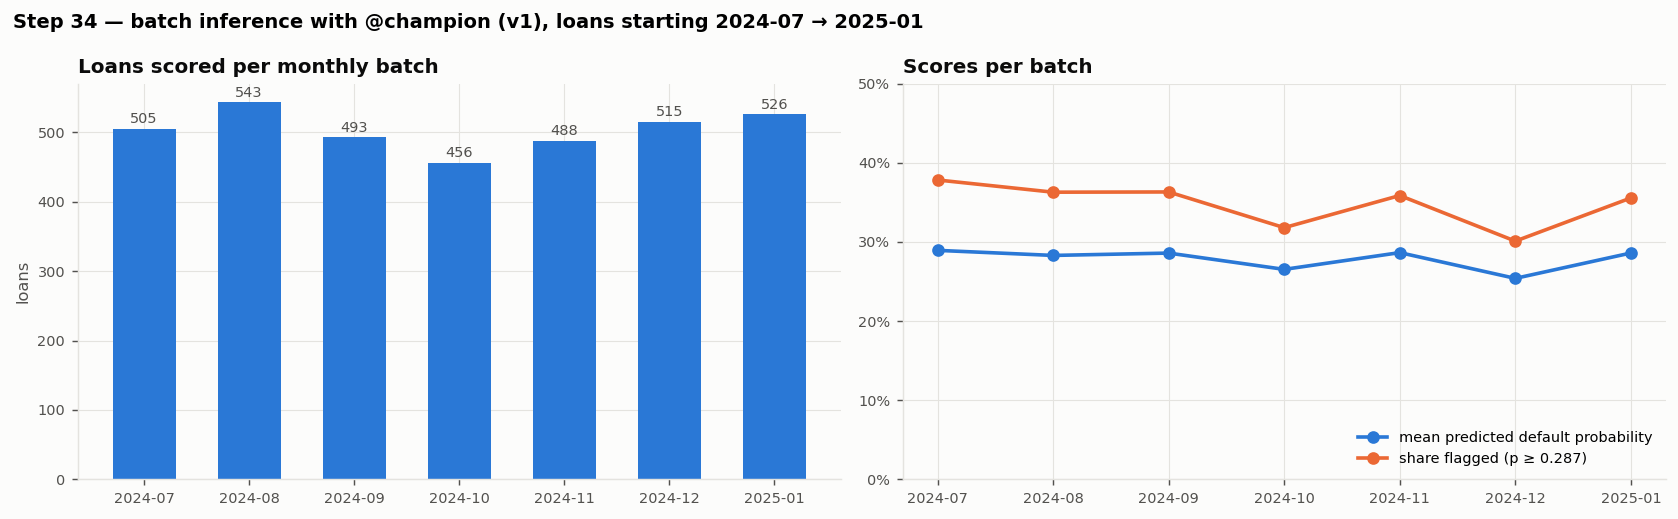

35_1_input_drift_heatmap.png


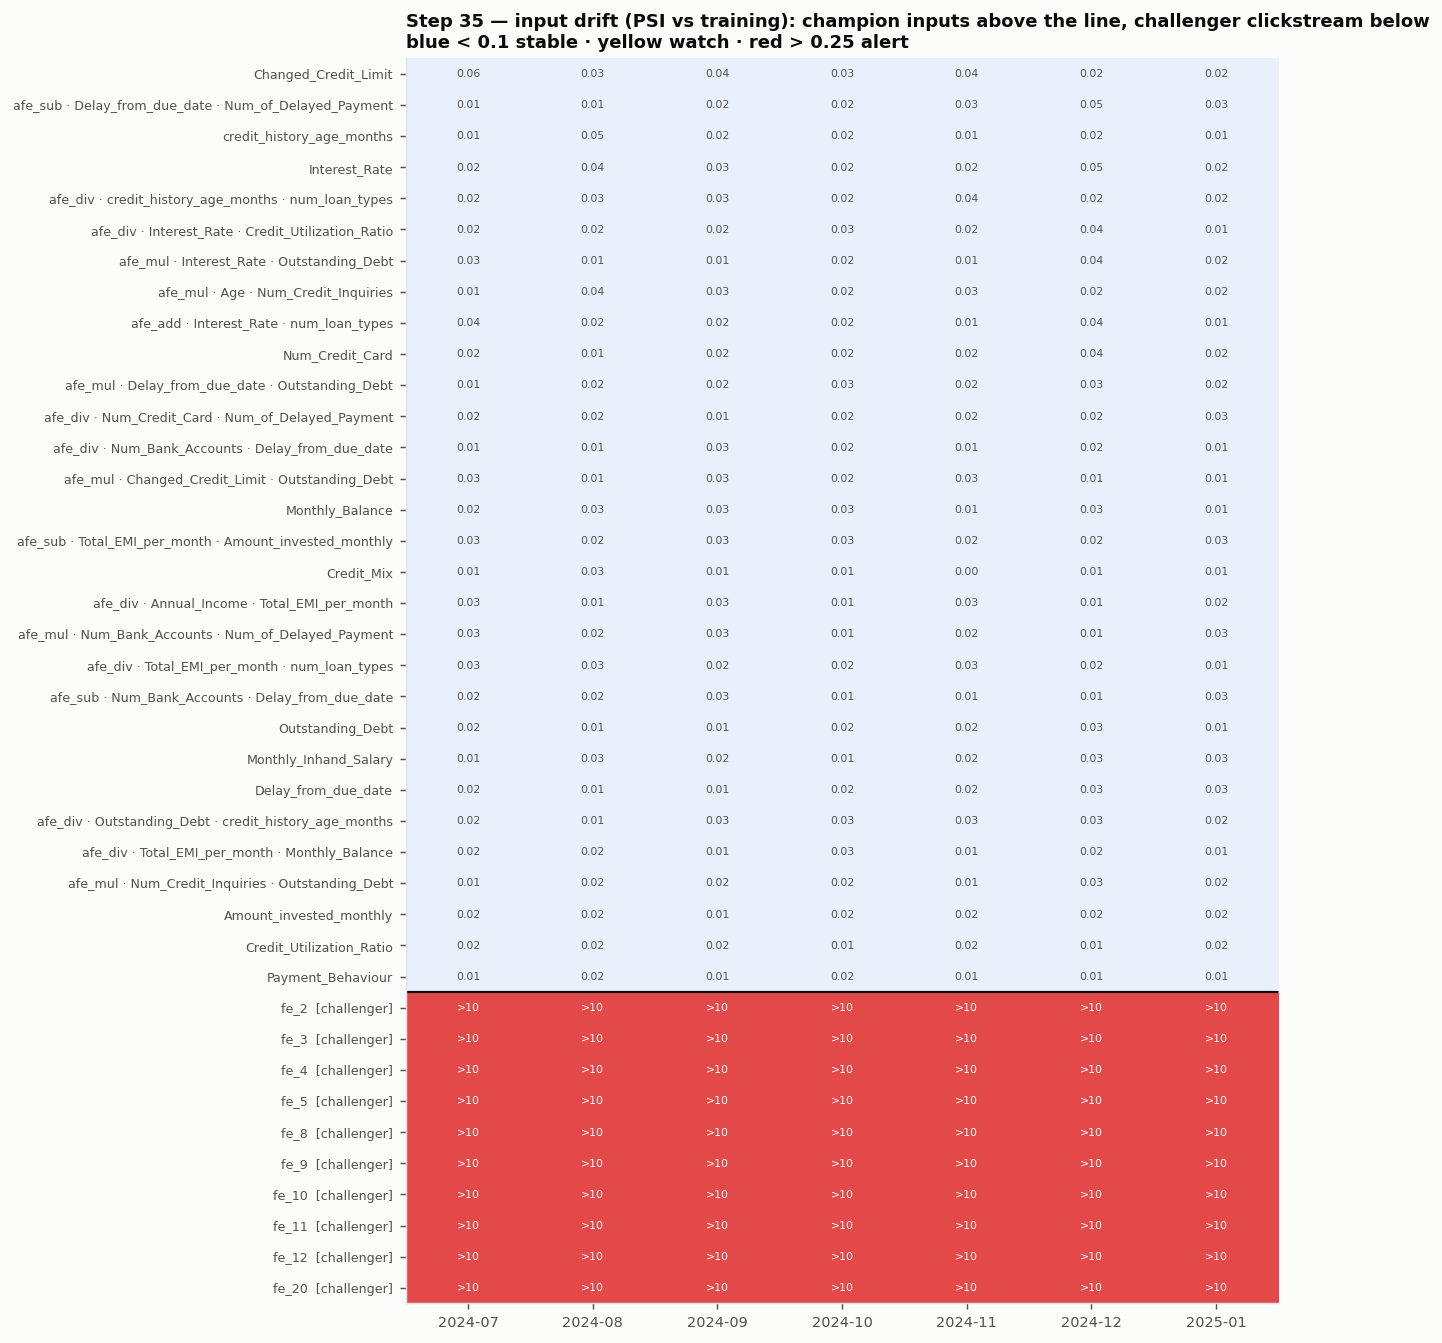

35_2_score_and_performance.png


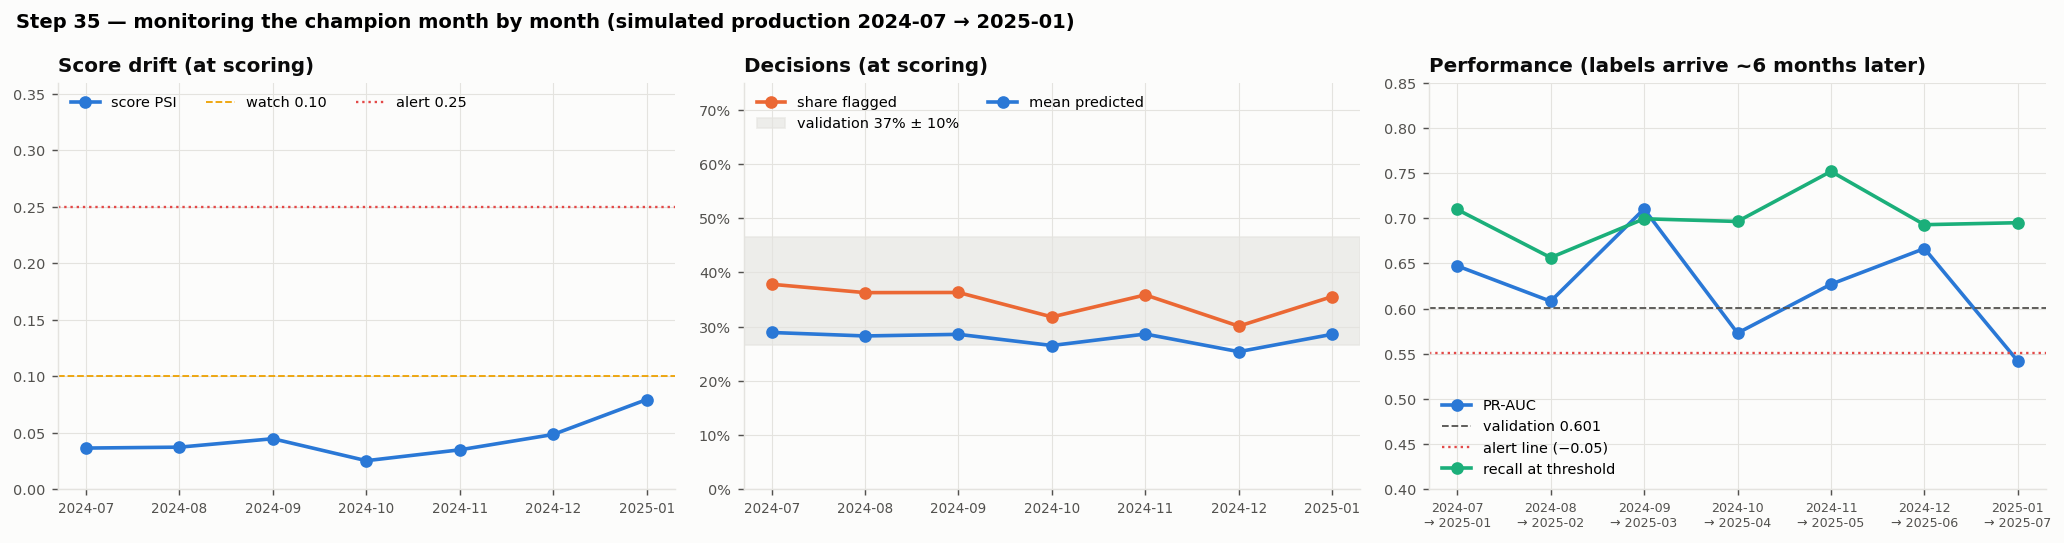

35_3_challenger_clickstream_missing.png


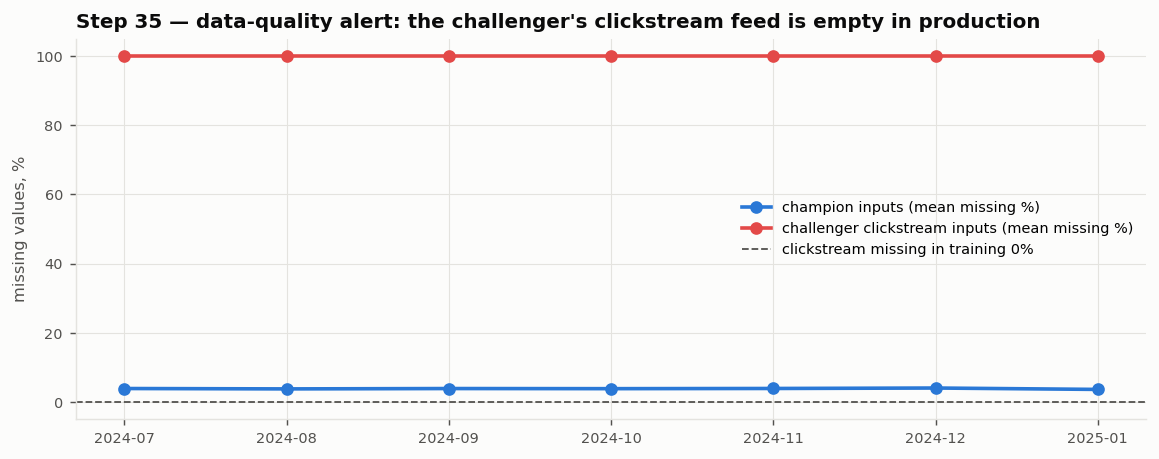

In [4]:
# Section 05 charts (saved by util/ml_deployment.py; explained in notebooks/ml_deployment.ipynb)
from IPython.display import Image
DEP_CHART_DIR = os.path.join(PROJECT_DIR, "datamart", "ml", "deployment", "v1", "charts")
for chart in ["34_1_batch_inference.png", "35_1_input_drift_heatmap.png", "35_2_score_and_performance.png",
              "35_3_challenger_clickstream_missing.png"]:
    print(chart)
    display(Image(filename=os.path.join(DEP_CHART_DIR, chart), width=1000))